# 02 · Preprocessing and forecasting samples

**Objective.** Turn the raw METR-LA matrix into leakage-free, reproducible forecasting samples that **every** model shares:
one chronological split, one training-only scaler, one missing-data policy, one window definition.

**Methodology.**
1. Interpret zeros as missing (`speed` with NaN + boolean `observed` mask).
2. Split **chronologically** at exact timestamps (70 / 10 / 20 %, snapped to midnight so each split holds whole days).
3. Preserve missingness information; decide per model family how it enters the model.
4. Fit the scaler on **training timestamps only**.
5. Calendar features and causal (past-only) helper arrays.
6. Generate windows: 12 past steps (60 min) -> targets at steps 1, 3, 6, 12 (5, 15, 30, 60 min); assert no leakage.
7. Save the processed artifacts that notebooks 03-08 reload.

All reusable logic is in `src/preprocessing.py`, `src/feature_engineering.py`; the unit tests are in `tests/test_splits.py`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : {ROOT}")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : /Users/ishanmaheshwari1/Desktop/AML-DLProject/traffic-flow-control
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, preprocessing as pp, feature_engineering as fe, visualization as viz

viz.apply_style()
dl.require_raw_files()

## 1 · Load the raw data and interpret missing readings

As established in notebook 01, `0.0` marks a missing reading. `to_speed_and_mask` converts it to `NaN` and records an
`observed` mask; negative values would raise an error. After this step **no array contains a zero speed**.

In [3]:
raw = dl.load_metr_la_h5()
speed, observed = dl.to_speed_and_mask(raw.values)
timestamps, sensor_ids = raw.timestamps, raw.sensor_ids
T, N = speed.shape
print(f"speed: {speed.shape} {speed.dtype} | observed mask: {observed.shape} {observed.dtype}")
print(f"missing share: {(~observed).mean():.2%}")
assert np.array_equal(np.isnan(speed), ~observed) and np.nanmin(speed) > 0

speed: (34272, 207) float32 | observed mask: (34272, 207) bool
missing share: 8.11%


## 2 · Chronological split with exact timestamp boundaries

* Boundaries are placed at the nearest **midnight** to the 70 % / 80 % marks, so each split contains complete days.
* No shuffling anywhere: train < validation < test in time.
* **Context rule.** A sample belongs to the split containing *all its targets*. Its 60-minute *input* window may reach
  back into the preceding split (that is legitimate past information at prediction time), but never forward.
  Consequently, training windows never see validation/test rows at all, and the first test forecasts use validation rows
  only as input history.

In [4]:
splits = pp.make_chronological_splits(timestamps)
rows = []
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    rows.append({"split": name, "start_idx": a, "end_idx (excl.)": b, "steps": b - a, "days": (b - a) / 288,
                 "share": (b - a) / T, "first timestamp": splits.first_timestamp[name], "last timestamp": splits.last_timestamp[name],
                 "weekdays covered": int(timestamps[a:b].dayofweek.nunique())})
split_table = pd.DataFrame(rows).set_index("split")
display(split_table)

# integrity assertions
assert splits.train[0] == 0 and splits.train[1] == splits.val[0] and splits.val[1] == splits.test[0] and splits.test[1] == T
assert pd.Timestamp(splits.last_timestamp["train"]) < pd.Timestamp(splits.first_timestamp["val"])
assert pd.Timestamp(splits.last_timestamp["val"]) < pd.Timestamp(splits.first_timestamp["test"])
assert all(timestamps[e].hour == 0 and timestamps[e].minute == 0 for e in (splits.train[1], splits.val[1]))
splits.to_json()
print("saved", config.SPLITS_JSON.relative_to(config.PROJECT_ROOT))

,start_idx,end_idx (excl.),steps,days,share,first timestamp,last timestamp,weekdays covered
split,,,,,,,,
train,0,23904,23904,83.0,0.697479,2012-03-01 00:00:00,2012-05-22 23:55:00,7
val,23904,27360,3456,12.0,0.100840,2012-05-23 00:00:00,2012-06-03 23:55:00,7
test,27360,34272,6912,24.0,0.201681,2012-06-04 00:00:00,2012-06-27 23:55:00,7


saved data/processed/splits.json


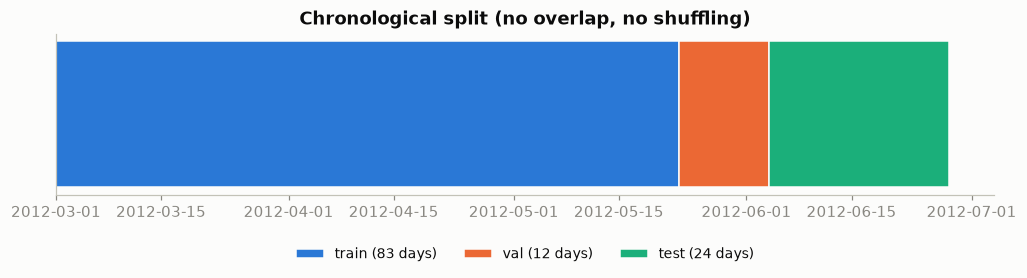

In [5]:
fig, ax = plt.subplots(figsize=(11, 1.9))
colors = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    ax.barh(0, timestamps[b - 1] - timestamps[a], left=timestamps[a], color=colors[name], edgecolor=viz.SURFACE, height=0.5, label=f"{name} ({(b - a) / 288:.0f} days)")
ax.set_yticks([]); ax.set_title("Chronological split (no overlap, no shuffling)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.grid(False); viz.save_figure(fig, "02_split_timeline"); plt.show()

**Interpretation.** The three periods are contiguous and disjoint; the last 24 days (the test period) are never touched during
fitting, scaling, early stopping or hyper-parameter selection. All models use these identical boundaries.
Because the periods are different calendar weeks, the test period may differ in conditions from the training period
(see the limitations in notebook 01).

## 3 · Missing values

| Where | Policy |
|---|---|
| **Targets** | A missing target is never predicted-against: it is excluded from every loss and metric (`observed` mask). |
| **Persistence / rolling mean** | Use the latest / mean of **observed** readings in the 60-minute window; if the whole window is missing, fall back to the sensor's *training* mean (never zero). |
| **XGBoost features** | Lags stay `NaN` (XGBoost learns a default direction for missing values); no imputation. |
| **ST-GAT inputs** | Value channel = scaled speed, `0` (= the training mean in scaled space) where missing, **plus** an explicit observed-mask channel. No value is copied from a neighbour or from the future. |
| **Anchor** | `last observed speed in the window` (causal last-observation-carried-forward limited to the window) with the training-mean fallback; used by persistence and as the residual base of both learned models. |

In [6]:
miss_summary = pp.missingness_summary(observed, splits)
display(miss_summary.round(3))
assert (miss_summary["missing_cells"].sum() == (~observed).sum())
ratio = miss_summary.loc["test", "missing_pct"] / miss_summary.loc["train", "missing_pct"]
print(f"missing share, test vs train: {miss_summary.loc['test', 'missing_pct']:.1f}% vs {miss_summary.loc['train', 'missing_pct']:.1f}% (x{ratio:.2f})")

,timesteps,cells,missing_cells,missing_pct,network_wide_outage_steps
split,,,,,
train,23904,4948128,354097,7.156,1301
val,3456,715392,49275,6.888,181
test,6912,1430784,171930,12.016,666


missing share, test vs train: 12.0% vs 7.2% (x1.68)


**Interpretation / caveat.** Missingness is **not** uniform across the splits: the test period contains noticeably more missing
data (and more network-wide outage steps) than the training period (printed above). Missing *targets* are simply excluded from
all metrics, so scores remain comparable between models, but test *inputs* are also more often incomplete. The anchor-fallback
rate in section 6 shows the same shift. This is a property of the data, not something we correct; it is reported again in the
final results.

## 4 · Scaling fitted on training timestamps only

A global z-score (`mean`, `std` of the **observed training** speeds) plus a per-sensor training mean (the fallback anchor).
The same fitted object transforms validation and test; nothing is ever refitted. To *demonstrate* the absence of leakage, we
wreck the validation/test rows and verify the fitted statistics do not change.

In [7]:
scaler = pp.SpeedScaler.fit(speed, observed, splits.train)
print(f"fit range (train)  : rows {scaler.fit_range}")
print(f"global mean / std  : {scaler.mean:.3f} / {scaler.std:.3f} mph")
print(f"per-sensor training mean: min {scaler.sensor_mean.min():.1f}  median {np.median(scaler.sensor_mean):.1f}  max {scaler.sensor_mean.max():.1f} mph")

# leakage test: destroy everything after the training period, refit, compare
tampered = speed.copy(); tampered[splits.val[0]:] = 12345.0
check = pp.SpeedScaler.fit(tampered, observed, splits.train)
assert check.mean == scaler.mean and check.std == scaler.std and np.array_equal(check.sensor_mean, scaler.sensor_mean)

# scaled statistics per split (only the training split is exactly standardised)
rows = []
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    z = scaler.transform(speed[a:b][observed[a:b]])
    rows.append({"split": name, "mean of scaled": z.mean(), "std of scaled": z.std()})
display(pd.DataFrame(rows).set_index("split").round(3))
assert abs(rows[0]["mean of scaled"]) < 1e-3 and abs(rows[0]["std of scaled"] - 1) < 1e-3
lo, hi = config.SPEED_BOUNDS_MPH
a, b = splits.train
assert np.nanmin(speed[a:b]) > lo and np.nanmax(speed[a:b]) <= hi, "training speeds fall outside the clipping range"
print(f"training speeds lie in ({np.nanmin(speed[a:b]):.2f}, {np.nanmax(speed[a:b]):.2f}] mph -> predictions are clipped to {config.SPEED_BOUNDS_MPH} when scored")

scaler.to_json()
print("saved", config.SCALER_JSON.relative_to(config.PROJECT_ROOT))

fit range (train)  : rows (0, 23904)
global mean / std  : 58.579 / 12.837 mph
per-sensor training mean: min 30.9  median 59.8  max 67.8 mph


,mean of scaled,std of scaled
split,,
train,-0.000,1.000
val,0.023,1.025
test,-0.060,1.059


training speeds lie in (0.33, 70.00] mph -> predictions are clipped to (0.0, 70.0) when scored
saved data/processed/scaler.json


**Interpretation.** The scaler is unaffected by what happens after the training period, as required. Validation and test are
transformed with the *training* statistics, so their scaled mean/std deviate from (0, 1); that deviation is expected and
is exactly what an honest deployment would experience.

## 5 · Temporal features

Calendar information about a timestamp is legitimately available in advance (we know what time and weekday it will be).
We create `sin/cos` of the minute-of-day and of the weekday (cyclical, so 23:55 is close to 00:00 and Sunday to Monday).
The tabular model additionally gets the calendar features of the **forecast target time**.

In [8]:
cal = pp.calendar_arrays(timestamps)
time_feats = pp.time_feature_matrix(timestamps)
display(pd.DataFrame({"timestamp": timestamps[[0, 100, 288 * 4 + 150]], "minute_of_day": cal["minute_of_day"][[0, 100, 288 * 4 + 150]],
                      "dow (Mon=0)": cal["dow"][[0, 100, 288 * 4 + 150]],
                      **{k: cal[k][[0, 100, 288 * 4 + 150]].round(3) for k in ("tod_sin", "tod_cos", "dow_sin", "dow_cos")}}))
assert time_feats.shape == (T, 4) and np.abs(time_feats).max() <= 1 + 1e-6
assert np.allclose(time_feats[0, :2], time_feats[288, :2])        # same time of day, one day later

,timestamp,minute_of_day,dow (Mon=0),tod_sin,tod_cos,dow_sin,dow_cos
0,2012-03-01 00:00:00,0.0,3,0.000,1.000,0.434,-0.901
1,2012-03-01 08:20:00,500.0,3,0.819,-0.574,0.434,-0.901
2,2012-03-05 12:30:00,750.0,0,-0.131,-0.991,0.000,1.000


## 6 · Causal helper arrays: last observation, age, and the anchor

`locf_with_age` carries the last observed value forward using **only the current and earlier rows**. From it we derive the
*anchor* of each sample (the most recent observed speed inside the 12-step input window, otherwise the sensor's training
mean). We verify causality by changing the future and checking that nothing earlier moves.

In [9]:
locf_value, locf_age = pp.locf_with_age(speed, observed)

future_wrecked = speed.copy(); future_wrecked[20000:] = 999.0
v2, a2 = pp.locf_with_age(future_wrecked, observed)
assert np.array_equal(np.nan_to_num(locf_value[:20000], nan=-1), np.nan_to_num(v2[:20000], nan=-1))
assert np.array_equal(locf_age[:20000], a2[:20000])
print("LOCF is causal: rows < 20000 are unchanged when rows >= 20000 are altered")

rows = []
for name in pp.SPLIT_NAMES:
    o = pp.valid_origins(splits.range(name), config.INPUT_LEN, config.MAX_HORIZON, T, name)
    _, used_fallback = pp.window_anchor(locf_value, locf_age, o, config.INPUT_LEN, scaler.sensor_mean)
    rows.append({"split": name, "origins": len(o), "anchor fell back to training mean": f"{used_fallback.mean():.2%}"})
display(pd.DataFrame(rows).set_index("split"))

LOCF is causal: rows < 20000 are unchanged when rows >= 20000 are altered


,origins,anchor fell back to training mean
split,,
train,23881,5.50%
val,3445,4.84%
test,6901,9.58%


## 7 · Window generation, shapes and leakage assertions

For an origin `t`: inputs are rows `t-11 ... t` and targets are rows `t+1 ... t+12`; models are evaluated at steps
`1, 3, 6, 12`. Origins are generated so that **all 12 target steps** lie in the sample's split.

In [10]:
L, H = config.INPUT_LEN, config.MAX_HORIZON
origins = {}
for name in pp.SPLIT_NAMES:
    origins[name] = pp.valid_origins(splits.range(name), L, H, T, name)
    pp.assert_no_leakage(origins[name], splits.range(name), L, H, T)       # raises on any violation

rows = []
for name in pp.SPLIT_NAMES:
    o = origins[name]; x_idx, y_idx = pp.window_index_arrays(o, L, H)
    rows.append({"split": name, "samples": len(o),
                 "first input row": int(x_idx.min()), "last input row": int(x_idx.max()),
                 "first target row": int(y_idx.min()), "last target row": int(y_idx.max()),
                 "split rows": str(splits.range(name))})
display(pd.DataFrame(rows).set_index("split"))

# train windows must never contain a validation or test row (neither as input nor as target)
x_tr, y_tr = pp.window_index_arrays(origins["train"], L, H)
assert x_tr.max() < splits.val[0] and y_tr.max() < splits.val[0]
# test windows may read validation rows as past context only
x_te, y_te = pp.window_index_arrays(origins["test"], L, H)
assert x_te.min() < splits.test[0] <= y_te.min()
print("temporal ordering verified: inputs <= origin < targets, targets inside their own split")

,samples,first input row,last input row,first target row,last target row,split rows
split,,,,,,
train,23881,0,23891,12,23903,"(0, 23904)"
val,3445,23892,27347,23904,27359,"(23904, 27360)"
test,6901,27348,34259,27360,34271,"(27360, 34272)"


temporal ordering verified: inputs <= origin < targets, targets inside their own split


In [11]:
# Tensor shapes for the graph model and the targets, on a small batch of test origins
batch = origins["test"][:8]
scaled_filled = pp.fill_for_model(speed, observed, scaler)
X = pp.gather_model_inputs(scaled_filled, observed, time_feats, batch, L)
Y, Y_obs = pp.gather_targets(speed, observed, batch, tuple(range(1, H + 1)))
Y_eval, Y_eval_obs = pp.gather_targets(speed, observed, batch, config.HORIZONS)
print(f"X (inputs)          : {X.shape}   = [batch, {L} steps, {N} sensors, 6 features]")
print("   channels         : 0 scaled speed (0 where missing) | 1 observed mask | 2-5 sin/cos time of day, sin/cos weekday")
print(f"Y (all 12 steps)    : {Y.shape}   = [batch, {H}, {N}] mph with NaN where missing; observed mask {Y_obs.shape}")
print(f"Y at {config.HORIZONS}  : {Y_eval.shape}  -> the evaluation targets (minutes {tuple(config.HORIZON_MINUTES[h] for h in config.HORIZONS)})")
assert X.shape == (8, L, N, 6) and Y.shape == (8, H, N)
assert np.array_equal(X[..., 1].astype(bool), observed[pp.window_index_arrays(batch, L, 1)[0]])   # mask channel == observed
assert np.isfinite(X).all()                     # model inputs never contain NaN
assert np.array_equal(Y_eval_obs, Y_obs[:, [h - 1 for h in config.HORIZONS]])

# leakage test: destroy all rows after the last origin of this batch; the inputs must not change
wrecked = scaled_filled.copy(); wrecked[batch.max() + 1:] = 1e6
X2 = pp.gather_model_inputs(wrecked, observed, time_feats, batch, L)
assert np.array_equal(X, X2)
print("inputs do not depend on any row after the origin")

X (inputs)          : (8, 12, 207, 6)   = [batch, 12 steps, 207 sensors, 6 features]
   channels         : 0 scaled speed (0 where missing) | 1 observed mask | 2-5 sin/cos time of day, sin/cos weekday
Y (all 12 steps)    : (8, 12, 207)   = [batch, 12, 207] mph with NaN where missing; observed mask (8, 12, 207)
Y at (1, 3, 6, 12)  : (8, 4, 207)  -> the evaluation targets (minutes (5, 15, 30, 60))
inputs do not depend on any row after the origin


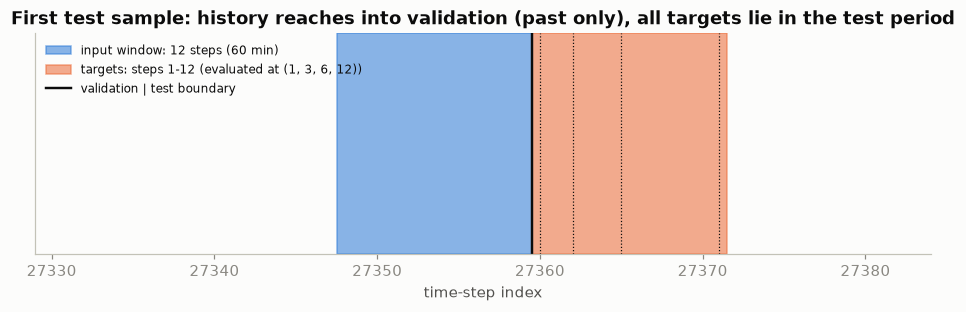

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 2.6))
o = int(origins["test"][0])
ax.axvspan(o - L + 1 - 0.5, o + 0.5, color="#2a78d6", alpha=0.55, label=f"input window: {L} steps (60 min)")
ax.axvspan(o + 0.5, o + H + 0.5, color="#eb6834", alpha=0.55, label=f"targets: steps 1-{H} (evaluated at {config.HORIZONS})")
for h in config.HORIZONS:
    ax.axvline(o + h, color=viz.INK, lw=0.8, ls=":")
ax.axvline(splits.test[0] - 0.5, color=viz.INK, lw=1.6, label="validation | test boundary")
ax.set_xlim(o - 30, o + 25); ax.set_yticks([]); ax.set_xlabel("time-step index"); ax.grid(False)
ax.set_title("First test sample: history reaches into validation (past only), all targets lie in the test period")
ax.legend(loc="upper left", fontsize=8, ncol=1); viz.save_figure(fig, "02_window_diagram"); plt.show()

**Interpretation.** Window generation is verified numerically, not only drawn: inputs end at the origin, targets start one
step after it, train windows are fully inside the training period, and the first test origin is the last row of validation,
whose forecasts all fall in the test period. The graph model's input tensor has the shape `[batch, 12, 207, 6]`.

## 8 · Tabular features for the per-sensor model (XGBoost)

One row per *(origin, sensor)*: 12 lags, rolling means (3, 6, 12 steps) and standard deviations (6, 12), a short-term trend,
the last observed speed and its age, calendar features of the **target** time, and static sensor descriptors
(`sensor_id`, latitude, longitude, training mean). All rolling features use only readings up to the origin, and **no feature uses
another sensor** (that would give the "independent" baseline spatial information).

In [13]:
loc = dl.load_sensor_locations().set_index("sensor_id").loc[sensor_ids]
demo = origins["test"][::1000]
base, base_names = fe.build_base_features(speed, locf_value, locf_age, scaler.sensor_mean, demo,
                                          loc["latitude"].to_numpy(), loc["longitude"].to_numpy())
hz, hz_names = fe.horizon_features(timestamps, demo, 6, N)
frame = fe.to_frame(base, base_names, hz, hz_names, N)
print(f"feature matrix for {len(demo)} origins: {frame.shape}  (= {len(demo)} x {N} rows, {frame.shape[1]} columns)")
print("columns:", list(frame.columns))
print(f"share of NaN per column (lags are NaN where the reading is missing): ")
display(frame.isna().mean().round(3).loc[["lag_0", "lag_11", "roll_mean_12", "roll_std_6", "last_observed", "target_tod_sin"]].to_frame("NaN share"))

# leakage test: wreck every row after the last origin of this demo set
wr = speed.copy(); wr[demo.max() + 1:] = 555.0
lv, la = pp.locf_with_age(wr, ~np.isnan(wr))
base2, _ = fe.build_base_features(wr, lv, la, scaler.sensor_mean, demo, loc["latitude"].to_numpy(), loc["longitude"].to_numpy())
assert np.array_equal(np.nan_to_num(base, nan=-1), np.nan_to_num(base2, nan=-1))
print("features do not depend on any row after the origin")

feature matrix for 7 origins: (1449, 30)  (= 7 x 207 rows, 30 columns)
columns: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'roll_mean_3', 'roll_mean_6', 'roll_mean_12', 'roll_std_6', 'roll_std_12', 'n_observed_window', 'trend_3', 'last_observed', 'age_last_observed', 'sensor_train_mean', 'latitude', 'longitude', 'target_tod_sin', 'target_tod_cos', 'target_dow_sin', 'target_dow_cos', 'target_is_weekend', 'sensor_id']
share of NaN per column (lags are NaN where the reading is missing): 


,NaN share
lag_0,0.160
lag_11,0.161
roll_mean_12,0.014
roll_std_6,0.017
last_observed,0.000
target_tod_sin,0.000


features do not depend on any row after the origin


## 9 · Save the processed data

`traffic_clean.npz` (speed with NaN, observed mask, timestamps, canonical sensor order) is what every later notebook loads,
together with `splits.json` and `scaler.json`. Windows themselves are not stored: they are cheap index operations
(`window_index_arrays`) and storing 207 x 12 x 24k floats would waste gigabytes.

In [14]:
clean = dl.CleanTraffic(speed=speed, mask=observed, timestamps=timestamps, sensor_ids=sensor_ids)
dl.save_clean_traffic(clean)

# round-trip check through the same loader the next notebooks use
ctx = pp.load_context()
assert np.array_equal(np.nan_to_num(ctx.speed, nan=-1), np.nan_to_num(speed, nan=-1)) and np.array_equal(ctx.mask, observed)
assert ctx.sensor_ids == sensor_ids and (ctx.timestamps == timestamps).all()
assert all(np.array_equal(ctx.origins[k], origins[k]) for k in pp.SPLIT_NAMES)

size_mb = config.TRAFFIC_CLEAN_NPZ.stat().st_size / 1e6
print(f"saved {config.TRAFFIC_CLEAN_NPZ.relative_to(config.PROJECT_ROOT)} ({size_mb:.1f} MB), splits.json, scaler.json")
display(pd.DataFrame({
    "split": list(pp.SPLIT_NAMES),
    "samples (origins)": [len(origins[k]) for k in pp.SPLIT_NAMES],
    "GAT input X": [f"[{len(origins[k])}, {L}, {N}, 6]" for k in pp.SPLIT_NAMES],
    "targets Y (12 steps)": [f"[{len(origins[k])}, {H}, {N}]" for k in pp.SPLIT_NAMES],
    "XGBoost rows per horizon": [f"{len(origins[k]) * N:,}" for k in pp.SPLIT_NAMES],
}).set_index("split"))
print("\nPreprocessing complete. Next: 03_graph_construction.ipynb")

saved data/processed/traffic_clean.npz (11.2 MB), splits.json, scaler.json


,samples (origins),GAT input X,targets Y (12 steps),XGBoost rows per horizon
split,,,,
train,23881,"[23881, 12, 207, 6]","[23881, 12, 207]","4,943,367"
val,3445,"[3445, 12, 207, 6]","[3445, 12, 207]","713,115"
test,6901,"[6901, 12, 207, 6]","[6901, 12, 207]","1,428,507"



Preprocessing complete. Next: 03_graph_construction.ipynb
